# ML Assignment 6 – K-Means / Hierarchical Clustering on Sales Data
**Problem Statement:** Implement K-Means clustering / hierarchical clustering on `sales_data_sample.csv` dataset. Determine the number of clusters using the elbow method.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('sales_data_sample.csv', encoding='unicode_escape')
print(df.shape)
df.head()

(2823, 25)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


In [4]:
# Select numeric features relevant to sales for clustering
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
X = df[features].dropna()
X.describe()

,QUANTITYORDERED,PRICEEACH,SALES,MSRP
count,2823.000000,2823.000000,2823.000000,2823.000000
mean,35.092809,83.658544,3553.889072,100.715551
std,9.741443,20.174277,1841.865106,40.187912
min,6.000000,26.880000,482.130000,33.000000
25%,27.000000,68.860000,2203.430000,68.000000
50%,35.000000,95.700000,3184.800000,99.000000
75%,43.000000,100.000000,4508.000000,124.000000
max,97.000000,100.000000,14082.800000,214.000000


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Elbow method to find the optimal number of clusters

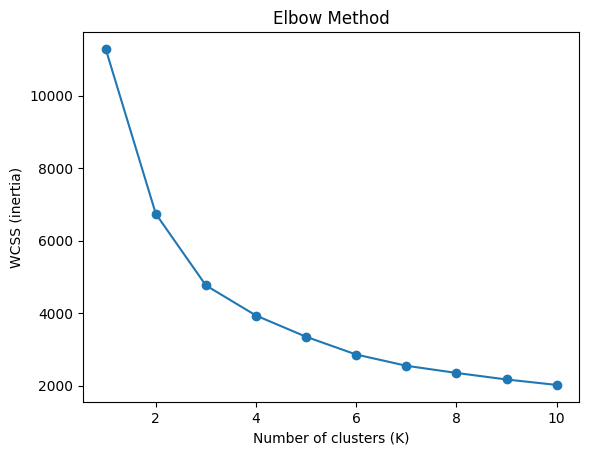

In [6]:
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)   # Within-Cluster Sum of Squares

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of clusters (K)'); plt.ylabel('WCSS (inertia)')
plt.title('Elbow Method'); plt.show()

The curve bends (elbow) at **K = 3**; after that WCSS decreases only slightly.

In [7]:
k = 3
kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
df.loc[X.index, 'KMeans_Cluster'] = kmeans.fit_predict(X_scaled)
print(df['KMeans_Cluster'].value_counts())
df.groupby('KMeans_Cluster')[features].mean()

KMeans_Cluster
2.0    996
0.0    975
1.0    852
Name: count, dtype: int64


,QUANTITYORDERED,PRICEEACH,SALES,MSRP
KMeans_Cluster,,,,
0.0,35.208205,59.551169,2101.076482,64.145641
1.0,43.723005,97.479261,5720.080669,127.893192
2.0,27.597390,95.435090,3123.062801,113.266064


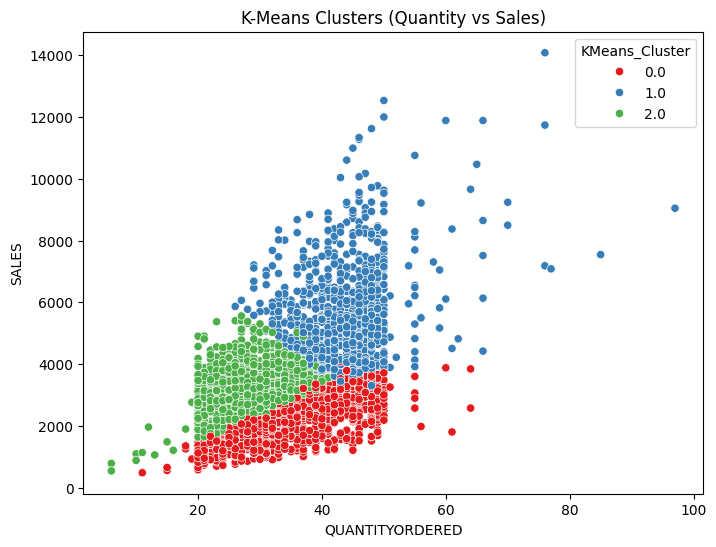

In [8]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=df['QUANTITYORDERED'], y=df['SALES'], hue=df['KMeans_Cluster'], palette='Set1')
plt.title('K-Means Clusters (Quantity vs Sales)'); plt.show()

## Hierarchical clustering

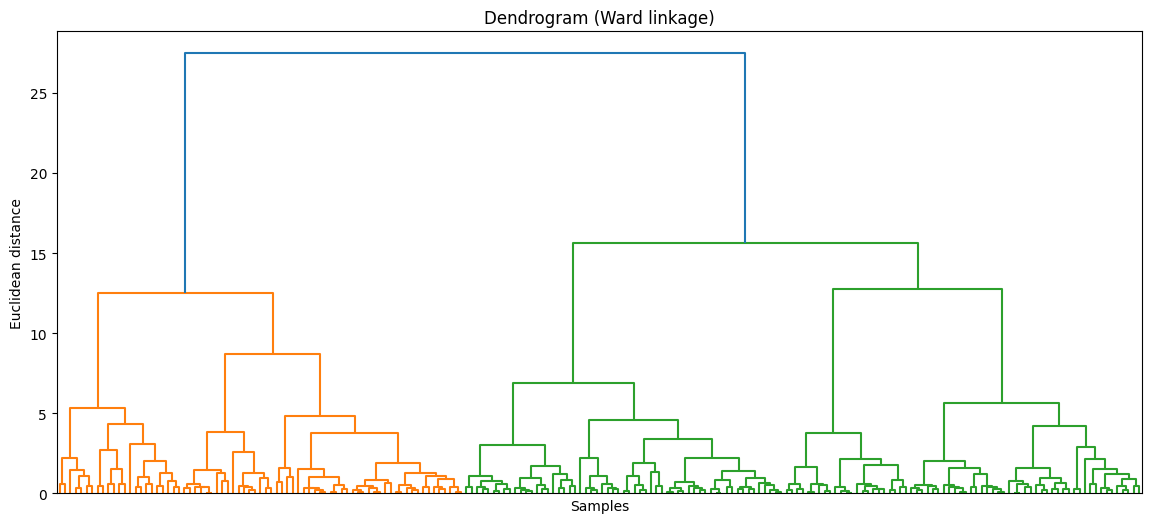

In [9]:
# Dendrogram on a sample (full data makes the plot unreadable)
sample = X_scaled[np.random.RandomState(42).choice(len(X_scaled), 200, replace=False)]
plt.figure(figsize=(14, 6))
dendrogram(linkage(sample, method='ward'), no_labels=True)
plt.title('Dendrogram (Ward linkage)'); plt.xlabel('Samples'); plt.ylabel('Euclidean distance'); plt.show()

In [10]:
hc = AgglomerativeClustering(n_clusters=k, linkage='ward')
df.loc[X.index, 'HC_Cluster'] = hc.fit_predict(X_scaled)
print(df['HC_Cluster'].value_counts())

HC_Cluster
0.0    1204
1.0     934
2.0     685
Name: count, dtype: int64


**Conclusion:** The elbow method gives K = 3 clusters (low, medium and high value orders). Hierarchical clustering with Ward linkage produces similar groups.